# DUA PULUH STASIUN CUACA

## Notebook Baseline Kaggle


### Ringkasan

Sebuah sistem lama mampu menghasilkan peta cuaca lengkap pada 400 lokasi.
Sistem tersebut akan dihentikan dan hanya 20 stasiun pengukuran permanen yang
dapat dipasang. Gunakan 20 pembacaan yang dapat berasal dari lokasi berbeda pada setiap baris, kemudian untuk
merekonstruksi keadaan pada seluruh 400 lokasi.

Masalah ini bukan hanya memilih lokasi yang tersebar secara geografis. Data
historis memperlihatkan pola global dan regional yang berulang. Lokasi yang
berdekatan sering berkaitan, tetapi beberapa fenomena dapat menghubungkan
wilayah yang berjauhan atau hanya terlihat jelas pada lokasi tertentu.


## 1. Deskripsi tugas

Dataset Kaggle menyediakan:

- `stations.csv`: ID dan koordinat 400 lokasi;
- `train.csv`: pengukuran historis lengkap pada `S000` sampai `S399`;
- `test.csv`: 20 pasangan `station_id_XX` dan `observed_XX` per baris;
- `sample_submission.csv`: urutan ID dan 400 kolom prediksi yang diwajibkan.

Kombinasi 20 stasiun dapat berbeda pada setiap baris data uji. Tugas peserta
adalah merekonstruksi seluruh 400 nilai dengan memanfaatkan identitas dan nilai
stasiun yang tersedia. Baseline paling sederhana ini menggunakan rata-rata
historis setiap stasiun untuk seluruh baris data uji.

Data uji terdiri dari kelompok `basic`, `main`, dan `robust`. Kelompok tersebut
memiliki tingkat noise dan gangguan sensor yang berbeda.


## 2. Metrik Evaluasi

Untuk setiap lokasi $j$, evaluator menghitung skala dari data training:

$$
s_j =
\max \left(
\mathrm{std}(X_{\mathrm{train},j}),
\;
0.5 \,
\underset{k}{\mathrm{median}}
\left[
\mathrm{std}(X_{\mathrm{train},k})
\right]
\right)
$$

Normalized Root Mean Squared Error (NRMSE) adalah:

$$
\mathrm{NRMSE}
=
\sqrt{
\frac{1}{np}
\sum_{i=1}^{n}
\sum_{j=1}^{p}
\left(
\frac{\hat{X}_{ij} - X_{ij}}{s_j}
\right)^2
}
$$

Nilai lebih kecil lebih baik.

Nilai akhir notebook adalah:

$$
0.20 E_{\mathrm{basic}}
+
0.60 E_{\mathrm{main}}
+
0.20 E_{\mathrm{robust}}
$$

Evaluator lokal di bawah memakai holdout dari training dan hanya merupakan
perkiraan skor. Nilai resmi dihitung Kaggle menggunakan baris **Public** dan
**Private** pada data tersembunyi.

## Hint

Walaupun tersedia 400 lokasi, perubahan nilai pada seluruh stasiun tidak sepenuhnya berdiri sendiri. Banyak kondisi cuaca tampaknya dapat dijelaskan sebagai gabungan dari sejumlah kecil pola yang berulang. Karena setiap lokasi dapat memiliki rata-rata dan besar variasi yang berbeda, pertimbangkan untuk terlebih dahulu menyetarakan skala data, kemudian mencari cara untuk merangkum 400 nilai tersebut menjadi beberapa pola utama. Operasi dekomposisi matriks dapat membantu menemukan pola-pola yang paling banyak menjelaskan variasi pada data historis.

Dua puluh stasiun yang baik bukan hanya stasiun dengan variasi terbesar atau yang paling tersebar secara geografis. Pilihlah lokasi-lokasi yang bersama-sama memberikan informasi yang saling melengkapi tentang pola utama tersebut; misalnya, lokasi dapat dipilih satu per satu berdasarkan seberapa banyak informasi baru yang ditambahkannya dan seberapa stabil seluruh kondisi dapat direkonstruksi dari lokasi yang sudah dipilih. Setelah 20 lokasi ditentukan, hubungan antara pembacaan pada lokasi tersebut dan nilai pada seluruh 400 lokasi dapat dipelajari dari data historis menggunakan pendekatan linear. Untuk menghadapi satu pembacaan yang rusak, periksa pula apakah suatu sensor tidak konsisten dengan nilai yang diperkirakan dari sensor-sensor lainnya.

In [37]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)

def cari_folder_data(berkas_wajib):
    """Cari folder dataset pada komputer lokal atau Kaggle."""
    kandidat = [Path("kaggle_data"), Path("../kaggle_data"), Path(".")]
    folder_kaggle = Path("/kaggle/input")
    if folder_kaggle.exists():
        kandidat.extend(path.parent for path in folder_kaggle.rglob(berkas_wajib))
    for folder in kandidat:
        if (folder / berkas_wajib).exists() and (folder / "sample_submission.csv").exists():
            return folder
    raise FileNotFoundError(f"Dataset Kaggle dengan berkas {berkas_wajib} tidak ditemukan")


JALUR_SUBMISSION = (
    Path("/kaggle/working/submission.csv")
    if Path("/kaggle/working").exists()
    else Path("submission.csv")
)

DATA_DIR = cari_folder_data("test.csv")
station_info = pd.read_csv(DATA_DIR / "stations.csv")
train_frame = pd.read_csv(DATA_DIR / "train.csv")
test_frame = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

station_columns = station_info["station_id"].tolist()
if station_columns != [kolom for kolom in train_frame.columns if kolom != "id"]:
    raise ValueError("Urutan station_id tidak cocok dengan kolom train.csv")

SENSOR_BUDGET = 20
STATION_COUNT = len(station_columns)
station_to_index = {station_id: i for i, station_id in enumerate(station_columns)}
station_id_columns = [f"station_id_{i:02d}" for i in range(SENSOR_BUDGET)]
observed_columns = [f"observed_{i:02d}" for i in range(SENSOR_BUDGET)]
expected_test_columns = ["id"] + [
    kolom for i in range(SENSOR_BUDGET)
    for kolom in (station_id_columns[i], observed_columns[i])
]
if test_frame.columns.tolist() != expected_test_columns:
    raise ValueError("Struktur pasangan station_id/observed pada test.csv tidak sesuai")

sample_ids = train_frame["id"].copy()
X_train = train_frame[station_columns].to_numpy(dtype=float)
TEST_STATION_INDICES = np.column_stack([
    test_frame[kolom].map(station_to_index).to_numpy()
    for kolom in station_id_columns
])
if pd.isna(TEST_STATION_INDICES).any():
    raise ValueError("test.csv memuat station_id yang tidak dikenal")
TEST_STATION_INDICES = TEST_STATION_INDICES.astype(int)
TEST_OBSERVED = test_frame[observed_columns].to_numpy(dtype=float)

print("Folder data       :", DATA_DIR.resolve())
print("Bentuk training   :", X_train.shape)
print("Bentuk data uji   :", test_frame.shape)
print("Jumlah panel unik :", len(np.unique(np.sort(TEST_STATION_INDICES, axis=1), axis=0)))
print("Panel baris pertama:", test_frame.loc[0, station_id_columns].tolist())


Folder data       : /kaggle/input/competitions/soal-2-2-final-ekka-2026/kaggle_data
Bentuk training   : (2500, 400)
Bentuk data uji   : (1400, 41)
Jumlah panel unik : 1400
Panel baris pertama: ['S074', 'S221', 'S192', 'S143', 'S017', 'S367', 'S286', 'S056', 'S047', 'S272', 'S248', 'S170', 'S332', 'S191', 'S013', 'S031', 'S004', 'S195', 'S206', 'S100']


In [38]:
test_frame

,id,station_id_00,observed_00,station_id_01,observed_01,station_id_02,...,station_id_17,observed_17,station_id_18,observed_18,station_id_19,observed_19
0,basic_F00000,S074,24.080944,S221,21.112140,S192,...,S195,20.508550,S206,24.220876,S100,24.553170
1,basic_F00001,S285,20.661995,S063,22.073304,S393,...,S206,22.867604,S045,24.717750,S074,25.471292
2,basic_F00002,S051,20.642533,S315,30.353772,S386,...,S156,18.845668,S397,15.450792,S203,26.026945
3,basic_F00003,S069,17.907675,S048,24.667349,S192,...,S080,23.102725,S036,24.477066,S267,25.118191
4,basic_F00004,S249,23.965960,S192,19.085514,S055,...,S188,21.906641,S247,24.887739,S159,22.068997
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1395,robust_F00395,S069,21.326753,S109,28.558864,S396,...,S276,22.869533,S300,22.715276,S260,24.808197
1396,robust_F00396,S155,17.654645,S207,25.963613,S185,...,S045,28.158464,S094,18.831197,S159,20.439442
1397,robust_F00397,S051,23.504710,S315,19.750386,S128,...,S106,26.123230,S300,23.589709,S354,22.802222
1398,robust_F00398,S069,21.157759,S374,10.065422,S257,...,S102,24.662431,S369,20.692677,S048,34.373505


## 3. Mengenal data secara visual

Plot berikut memperlihatkan susunan lokasi, nilai rata-rata, besar variasi,
dan beberapa contoh snapshot. Urutan `station_id` sengaja tidak mengikuti
urutan posisi pada grid; gunakan koordinat dari `stations.csv` apabila
diperlukan.


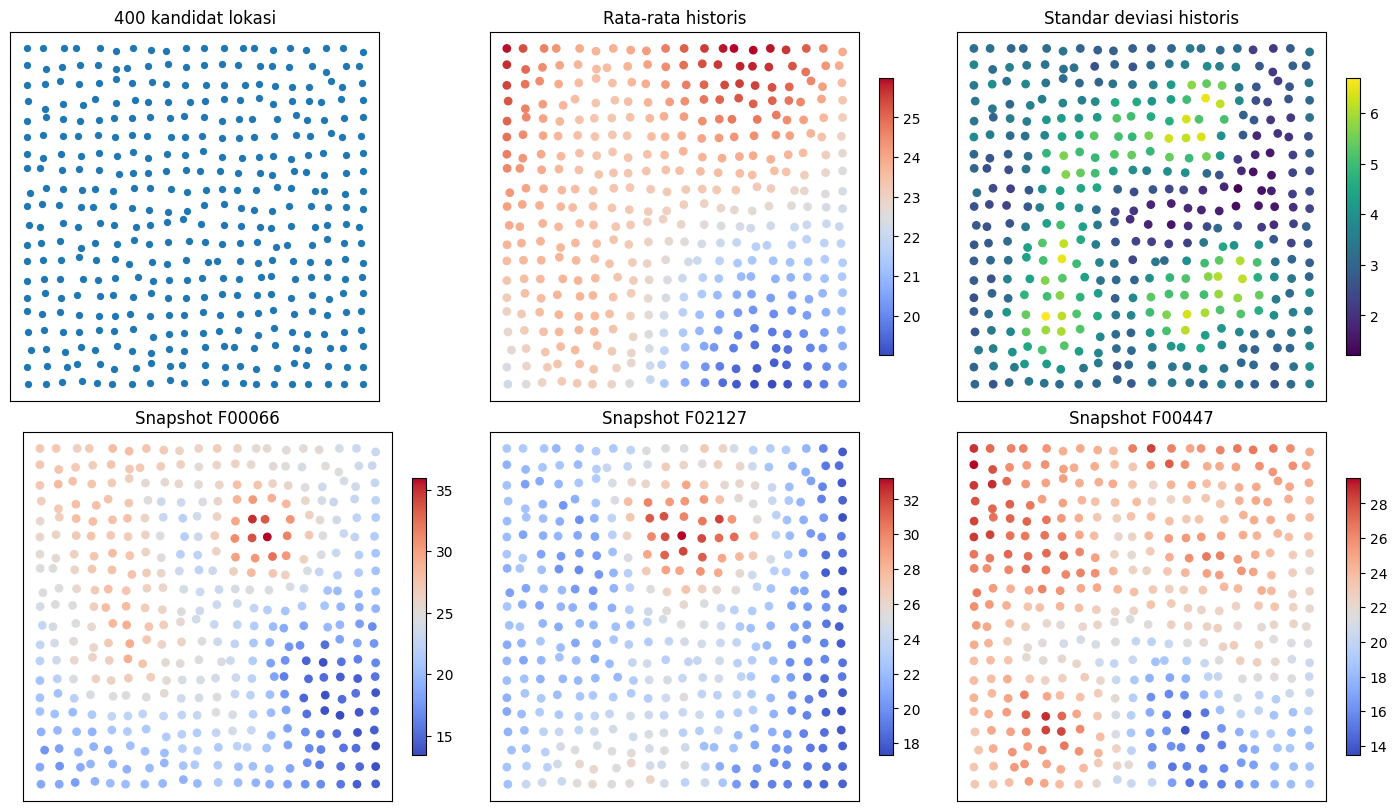

In [39]:
coordinates = station_info[["x", "y"]].to_numpy()
mean_field = X_train.mean(axis=0)
std_field = X_train.std(axis=0, ddof=1)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)

axes[0, 0].scatter(coordinates[:, 0], coordinates[:, 1], s=18, color="tab:blue")
axes[0, 0].set_title("400 kandidat lokasi")

mean_plot = axes[0, 1].scatter(
    coordinates[:, 0], coordinates[:, 1],
    c=mean_field, cmap="coolwarm", s=28
)
axes[0, 1].set_title("Rata-rata historis")
fig.colorbar(mean_plot, ax=axes[0, 1], shrink=0.75)

std_plot = axes[0, 2].scatter(
    coordinates[:, 0], coordinates[:, 1],
    c=std_field, cmap="viridis", s=28
)
axes[0, 2].set_title("Standar deviasi historis")
fig.colorbar(std_plot, ax=axes[0, 2], shrink=0.75)

for row, ax in zip(example_rows, axes[1]):
    snapshot = ax.scatter(
        coordinates[:, 0], coordinates[:, 1],
        c=X_train[row], cmap="coolwarm", s=28
    )
    ax.set_title(f"Snapshot {sample_ids.iloc[row]}")
    fig.colorbar(snapshot, ax=ax, shrink=0.75)

for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")

plt.show()


Lokasi berdekatan sering memiliki perilaku mirip, tetapi jarak bukan
satu-satunya sumber hubungan. Plot berikut mengambil pasangan lokasi secara
acak dan membandingkan jarak geografis dengan korelasi historisnya.


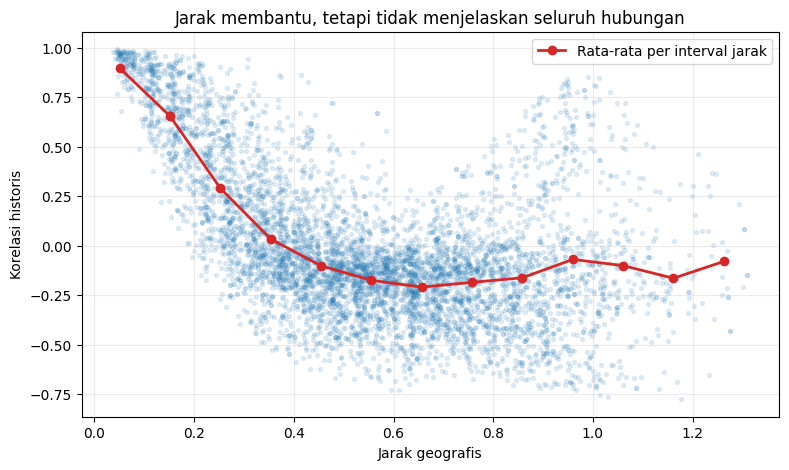

In [40]:
correlation = np.corrcoef(X_train, rowvar=False)
rng = np.random.default_rng(17)
pair_count = 6000
left = rng.integers(0, len(station_info), size=pair_count)
right = rng.integers(0, len(station_info), size=pair_count)
different = left != right
left = left[different]
right = right[different]

pair_distance = np.sqrt(np.sum(
    (coordinates[left] - coordinates[right]) ** 2,
    axis=1,
))
pair_correlation = correlation[left, right]

bins = np.linspace(0.0, np.sqrt(2.0), 15)
bin_id = np.digitize(pair_distance, bins) - 1
bin_center = 0.5 * (bins[:-1] + bins[1:])
bin_mean = np.array([
    pair_correlation[bin_id == k].mean() if np.any(bin_id == k) else np.nan
    for k in range(len(bin_center))
])

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(pair_distance, pair_correlation, s=8, alpha=0.12, color="tab:blue")
ax.plot(bin_center, bin_mean, color="tab:red", marker="o", linewidth=2,
        label="Rata-rata per interval jarak")
ax.set_xlabel("Jarak geografis")
ax.set_ylabel("Korelasi historis")
ax.set_title("Jarak membantu, tetapi tidak menjelaskan seluruh hubungan")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


Beberapa pertanyaan eksplorasi yang dapat dipertimbangkan:

- Apakah ratusan kolom tersebut benar-benar membawa 400 dimensi informasi
  yang independen?
- Apakah lokasi dengan variasi terbesar selalu membawa informasi yang berbeda?
- Bagaimana mengukur apakah dua calon sensor bersifat redundan?
- Bagaimana merekonstruksi seluruh field dari pengamatan yang tidak lengkap?
- Bagaimana mendeteksi satu pengamatan yang tidak konsisten dengan 19 sensor
  lainnya?


## 4. Evaluator lokal

Evaluator lokal memisahkan sebagian data training sebagai kebenaran tersembunyi.
Untuk setiap baris validasi, evaluator membuat panel D-optimal teracak berisi
20 stasiun berdasarkan representasi SVD data pengembangan. Noise dan pencilan
ditambahkan setelah panel setiap baris ditentukan.


In [41]:
def metric_scale(nilai_latih):
    skala = nilai_latih.std(axis=0, ddof=1)
    return np.maximum(skala, 0.5 * np.median(skala))


def normalized_rmse(kebenaran, prediksi, skala):
    return float(np.sqrt(np.mean(((prediksi - kebenaran) / skala) ** 2)))


def svd_loading(nilai, rank=14):
    rata = nilai.mean(axis=0)
    skala = metric_scale(nilai)
    standar = (nilai - rata) / skala
    _, singular, vt = np.linalg.svd(standar, full_matrices=False)
    return vt[:rank].T * np.sqrt(singular[:rank] ** 2 / (len(standar) - 1))[None, :]


def make_variable_panels(loading, jumlah_panel, seed, candidate_pool=12):
    """Buat panel D-optimal yang informatif tetapi bervariasi antarbaris."""
    rng = np.random.default_rng(seed)
    jumlah_stasiun, rank = loading.shape
    panels = np.empty((jumlah_panel, SENSOR_BUDGET), dtype=int)
    for nomor_panel in range(jumlah_panel):
        posterior = np.eye(rank)
        selected = []
        for posisi in range(SENSOR_BUDGET):
            information = np.einsum("ij,jk,ik->i", loading, posterior, loading)
            information[selected] = -np.inf
            ukuran_pool = min(candidate_pool, jumlah_stasiun - posisi)
            kandidat = np.argpartition(information, -ukuran_pool)[-ukuran_pool:]
            bobot = np.maximum(information[kandidat], 0.0)
            bobot /= bobot.sum()
            station = int(rng.choice(kandidat, p=bobot))
            selected.append(station)
            row = loading[station]
            direction = posterior @ row
            posterior -= np.outer(direction, direction) / (0.018 + row @ direction)
        panels[nomor_panel] = selected
    return panels


def validate_panels(panels, jumlah_baris):
    panels = np.asarray(panels)
    if panels.shape != (jumlah_baris, SENSOR_BUDGET):
        raise ValueError("Bentuk indeks panel tidak sesuai")
    if panels.min() < 0 or panels.max() >= STATION_COUNT:
        raise ValueError("Indeks stasiun berada di luar rentang")
    if any(len(np.unique(row)) != SENSOR_BUDGET for row in panels):
        raise ValueError("Setiap baris harus menggunakan 20 stasiun unik")
    return panels.astype(int)


def simulate_observations(truth, panels, skala, seed, noise_level, fault_rate=0.0):
    rng = np.random.default_rng(seed)
    rows = np.arange(len(truth))[:, None]
    full_noise = rng.normal(0.0, noise_level * skala, size=truth.shape)
    observed = truth[rows, panels] + full_noise[rows, panels]
    faulty = rng.random(len(truth)) < fault_rate
    positions = rng.integers(0, SENSOR_BUDGET, size=len(truth))
    bad_rows = np.flatnonzero(faulty)
    bad_pos = positions[bad_rows]
    observed[bad_rows, bad_pos] += (
        rng.choice([-1.0, 1.0], size=len(bad_rows))
        * rng.uniform(0.8, 1.5, size=len(bad_rows))
        * skala[panels[bad_rows, bad_pos]]
    )
    return observed


def validate_prediction(prediksi, jumlah_sampel):
    prediksi = np.asarray(prediksi, dtype=float)
    if prediksi.shape != (jumlah_sampel, STATION_COUNT):
        raise ValueError("Bentuk keluaran prediksi tidak sesuai")
    if not np.isfinite(prediksi).all():
        raise ValueError("Keluaran mengandung NaN atau infinity")
    return prediksi


def evaluate_local(KelasSolusi, nilai, lokasi, seed=73021):
    rng = np.random.default_rng(seed)
    urutan = rng.permutation(len(nilai))
    batas = int(0.80 * len(nilai))
    pengembangan, validasi = nilai[urutan[:batas]], nilai[urutan[batas:]]
    model = KelasSolusi()
    awal = time.perf_counter()
    model.fit(pengembangan.copy(), lokasi.copy())
    waktu_latih = time.perf_counter() - awal
    skala = metric_scale(pengembangan)
    loading = svd_loading(pengembangan)
    n_basic, n_main = int(0.20 * len(validasi)), int(0.60 * len(validasi))
    kelompok = {
        "basic": (validasi[:n_basic], 0.015, 0.0, 0.20, seed + 1),
        "main": (validasi[n_basic:n_basic+n_main], 0.035, 0.0, 0.60, seed + 2),
        "robust": (validasi[n_basic+n_main:], 0.035, 0.35, 0.20, seed + 3),
    }
    hasil, galat_tertimbang, waktu_prediksi = {}, 0.0, 0.0
    for nama, (benar, noise, rusak, bobot, seed_kelompok) in kelompok.items():
        panels = make_variable_panels(loading, len(benar), seed_kelompok + 100_000)
        observed = simulate_observations(benar, panels, skala, seed_kelompok, noise, rusak)
        awal = time.perf_counter()
        prediksi = validate_prediction(model.predict(observed, panels), len(benar))
        waktu_prediksi += time.perf_counter() - awal
        galat = normalized_rmse(benar, prediksi, skala)
        hasil[nama] = galat
        galat_tertimbang += bobot * galat
    hasil.update(weighted_nrmse=galat_tertimbang, fit_seconds=waktu_latih,
                 predict_seconds=waktu_prediksi)
    return pd.DataFrame([hasil], index=[KelasSolusi.__name__]), model


## 5. Baseline rata-rata historis

Baseline menghitung rata-rata setiap kolom `S000` sampai `S399` dari data
training, lalu menggunakan vektor rata-rata tersebut untuk seluruh baris uji.
Metode ini sengaja tidak memanfaatkan 20 pengamatan pada test dan dapat menjadi
titik awal untuk mengembangkan metode rekonstruksi yang lebih baik.


In [ ]:
class Solution:
    """Rekonstruksi SVD: standarkan, proyeksi rank-14 robust, kembalikan ke skala awal.

    Dipilih via evaluator lokal: rank=14, ridge=0.0005, Huber delta=1.345
    (weighted NRMSE ~0.19 vs ~1.0 baseline rata-rata).
    """
    def __init__(self, rank=14, lam=0.0005, huber=1.345, n_iter=10):
        self.rank = rank
        self.lam = lam
        self.huber = huber
        self.n_iter = n_iter

    def fit(self, train_values, station_info):
        train_values = np.asarray(train_values, dtype=float)
        self.mean_ = train_values.mean(axis=0)
        std = train_values.std(axis=0, ddof=1)
        self.scale_ = np.maximum(std, 0.5 * np.median(std))
        standar = (train_values - self.mean_) / self.scale_
        _, _, vt = np.linalg.svd(standar, full_matrices=False)
        self.basis_ = vt[:self.rank].T  # 400 x rank
        return self

    def _solve_row(self, matrix, vektor):
        identitas = np.eye(self.basis_.shape[1])
        gram = matrix.T @ matrix + self.lam * identitas
        try:
            laten = np.linalg.solve(gram, matrix.T @ vektor)
        except np.linalg.LinAlgError:
            laten = np.linalg.lstsq(gram, matrix.T @ vektor, rcond=None)[0]
        for _ in range(self.n_iter):
            sisa = vektor - matrix @ laten
            mutlak = np.abs(sisa)
            bobot = np.where(mutlak <= self.huber, 1.0,
                             self.huber / np.maximum(mutlak, 1e-12))
            akar = np.sqrt(bobot)
            terbobot = matrix * akar[:, None]
            target = akar * vektor
            gram = terbobot.T @ terbobot + self.lam * identitas
            try:
                baru = np.linalg.solve(gram, terbobot.T @ target)
            except np.linalg.LinAlgError:
                baru = np.linalg.lstsq(gram, terbobot.T @ target, rcond=None)[0]
            if np.allclose(baru, laten, rtol=1e-4, atol=1e-6):
                laten = baru
                break
            laten = baru
        return laten

    def predict(self, observed_values, station_indices):
        observed_values = np.asarray(observed_values, dtype=float)
        station_indices = validate_panels(station_indices, len(observed_values))
        jumlah = len(observed_values)
        keluaran = np.empty((jumlah, self.basis_.shape[0]))
        for i in range(jumlah):
            panel = station_indices[i]
            standar_obs = ((observed_values[i] - self.mean_[panel])
                           / self.scale_[panel])
            laten = self._solve_row(self.basis_[panel], standar_obs)
            keluaran[i] = self.mean_ + self.scale_ * (self.basis_ @ laten)
        return keluaran


In [43]:
model_final = Solution()
model_final.fit(X_train, station_info)
prediksi_uji = validate_prediction(
    model_final.predict(TEST_OBSERVED, TEST_STATION_INDICES), len(test_frame)
)

In [44]:
prediksi_uji

array([[39.6825, 12.6878, 12.3359, ..., 10.2389,  7.3052,  9.2525],
       [39.6825, 12.6878, 12.3359, ..., 10.2389,  7.3052,  9.2525],
       [39.6825, 12.6878, 12.3359, ..., 10.2389,  7.3052,  9.2525],
       ...,
       [39.6825, 12.6878, 12.3359, ..., 10.2389,  7.3052,  9.2525],
       [39.6825, 12.6878, 12.3359, ..., 10.2389,  7.3052,  9.2525],
       [39.6825, 12.6878, 12.3359, ..., 10.2389,  7.3052,  9.2525]])

## 6. Menguji baseline secara lokal

Gunakan fungsi yang sama setiap kali membandingkan solusi agar perbedaan skor
tidak disebabkan oleh pembagian data atau noise yang berbeda.


In [45]:
local_report, baseline_model = evaluate_local(
    Solution, X_train, station_info
)
print(local_report.round(4).to_string())


           basic   main  robust  weighted_nrmse  fit_seconds  predict_seconds
Solution  5.0257  5.048  5.0154           5.037       0.0057           0.0038


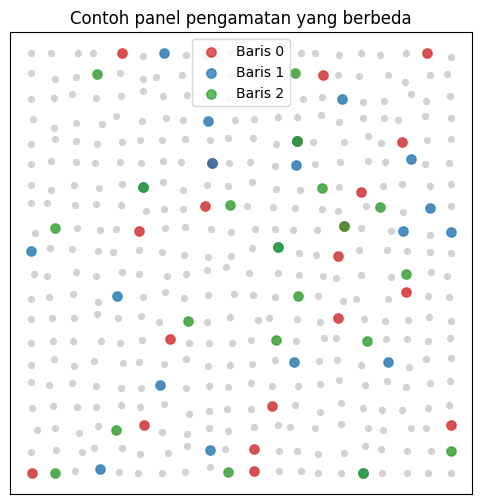

In [46]:
coordinates = station_info[["x", "y"]].to_numpy()
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(coordinates[:, 0], coordinates[:, 1], color="lightgray", s=18)
for row, color in zip(range(3), ["tab:red", "tab:blue", "tab:green"]):
    panel = TEST_STATION_INDICES[row]
    ax.scatter(coordinates[panel, 0], coordinates[panel, 1], s=45,
               alpha=0.75, color=color, label=f"Baris {row}")
ax.set_title("Contoh panel pengamatan yang berbeda")
ax.set_xticks([])
ax.set_yticks([])
ax.set_aspect("equal")
ax.legend()
plt.show()


## 7. Membuat `submission.csv`

Model dilatih pada seluruh data historis. Prediksi menggunakan pasangan nilai
dan ID stasiun pada setiap baris `test.csv`, lalu dimasukkan ke template agar
urutan ID serta kolom `S000` sampai `S399` tetap benar.


In [ ]:
model_final = Solution()
model_final.fit(X_train, station_info)
prediksi_uji = validate_prediction(
    model_final.predict(TEST_OBSERVED, TEST_STATION_INDICES), len(test_frame)
)

submission = sample_submission.copy()
if submission["id"].tolist() != test_frame["id"].tolist():
    raise ValueError("Urutan ID test dan sample submission tidak cocok")
submission.loc[:, station_columns] = prediksi_uji
submission.to_csv(JALUR_SUBMISSION, index=False)

print("Bentuk prediksi:", prediksi_uji.shape)
print("Submission ditulis ke:", JALUR_SUBMISSION)
display(submission.iloc[:5, :9])


## 8. Pemeriksaan akhir

Jalankan **Restart & Run All**. Pastikan seluruh panel berisi 20 stasiun unik,
seluruh prediksi finite, dan `submission.csv` memiliki kolom `id` serta
`S000` sampai `S399`. Unggah hanya `submission.csv` ke Kaggle.
